<a href="https://colab.research.google.com/github/niya-c-anto/ASSIGNMENTS/blob/main/CNN_MNIST_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

Load Mnist dataset

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
print("x_train", x_train.shape)

x_train (60000, 28, 28)


In [ ]:
print("y_train", y_train.shape)

y_train (60000,)


In [ ]:
print("x_test", x_test.shape)

x_test (10000, 28, 28)


In [ ]:
print("y_test", y_test.shape)

y_test (10000,)


Preprocessing images

In [ ]:
x_train = x_train.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

In [ ]:
x_test = x_test.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

Class Labels

In [ ]:
class_names = [str(i) for i in range(10)]
print(class_names)

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


Sample image plotting

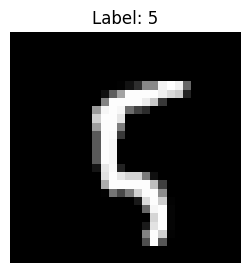

In [ ]:
def plot_sample(x, y, index):
  plt.figure(figsize = (3, 3))
  plt.imshow(x[index].squeeze(), cmap= 'gray')
  plt.title(f"Label: {class_names[y[index]]}")
  plt.axis("off")
  plt.show()

plot_sample(x_train, y_train, 100)

Build CNN Model

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation = 'relu', input_shape = (28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3,3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation = 'relu'),
    layers.Dense(10, activation = 'softmax')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Compile
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
history = model.fit(x_train, y_train,
                    epochs=10,
                    batch_size=64,
                    validation_data=(x_test, y_test))


Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 51s 53ms/step - accuracy: 0.8914 - loss: 0.3654 - val_accuracy: 0.9841 - val_loss: 0.0494
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.9857 - loss: 0.0475 - val_accuracy: 0.9877 - val_loss: 0.0354
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 51ms/step - accuracy: 0.9906 - loss: 0.0298 - val_accuracy: 0.9889 - val_loss: 0.0353
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 52ms/step - accuracy: 0.9935 - loss: 0.0212 - val_accuracy: 0.9914 - val_loss: 0.0268
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 54ms/step - accuracy: 0.9943 - loss: 0.0177 - val_accuracy: 0.9908 - val_loss: 0.0300
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 53ms/step - accuracy: 0.9955 - loss: 0.0123 - val_accuracy: 0.9917 - val_loss: 0.0265
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - accuracy: 0.9964 - loss: 0.0111 - val_accuracy: 0.9931 - val_loss: 0.0220
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 52ms/step - accuracy: 0.9982 - loss: 0.0065 - 

In [ ]:
# Evaluate
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"\n✅ Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9910 - loss: 0.0306

✅ Test Accuracy: 99.28%


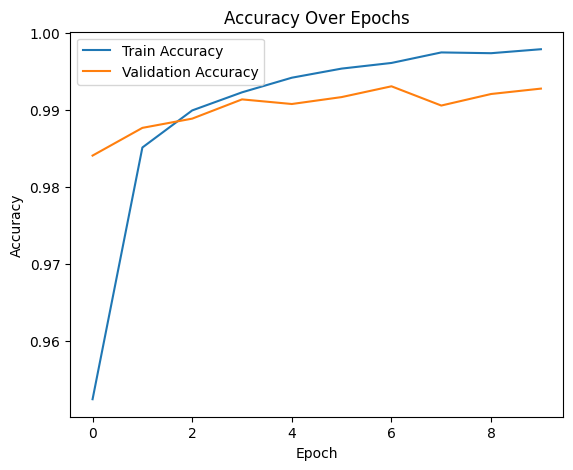

In [ ]:
# Plot Accuracy and Loss
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

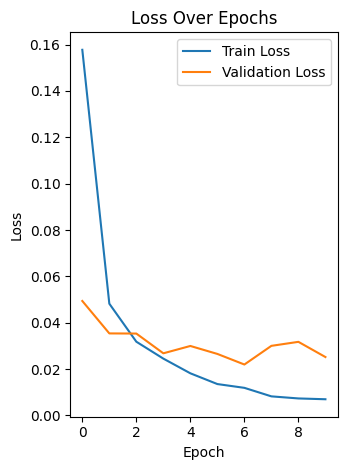

In [ ]:
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

# Predict on test set
y_pred_probs = model.predict(x_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


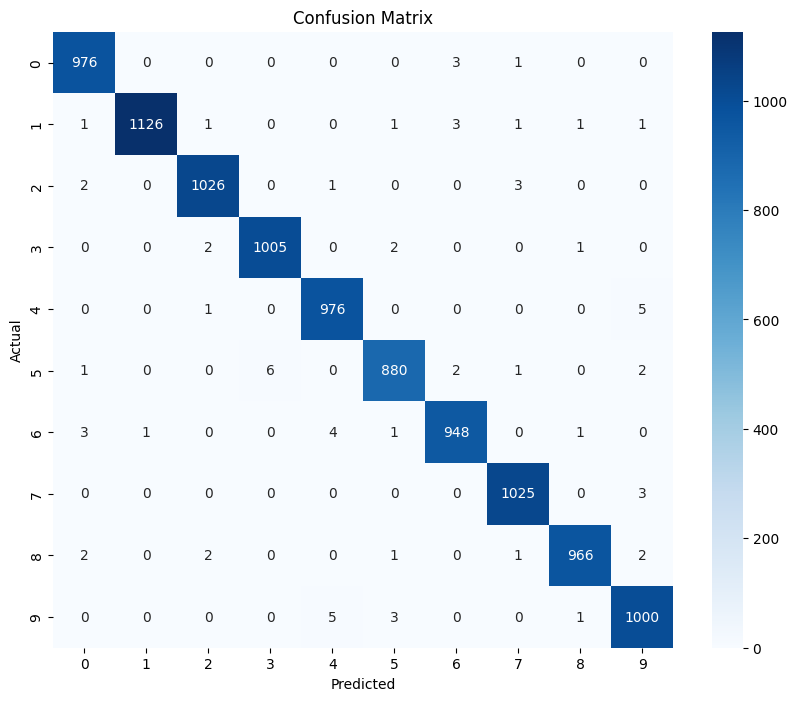

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
# Classification Report
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=class_names))


📊 Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      1.00      1.00      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



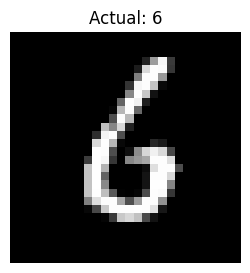

In [ ]:
sample_index = 50
plt.figure(figsize=(3,3))
plt.imshow(x_test[sample_index].squeeze(), cmap='gray')
plt.title(f"Actual: {class_names[y_test[sample_index]]}")
plt.xlabel(f"Predicted: {class_names[y_pred_classes[sample_index]]}")
plt.axis('off')
plt.show()